In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path
import urllib.request
import zipfile

In [2]:
sns.set_theme(style='whitegrid')
plt.rcParams['figure.figsize'] = (8, 5)

In [3]:
data_dir = Path('data')
data_dir.mkdir(exist_ok=True)

url = 'https://archive.ics.uci.edu/static/public/228/sms+spam+collection.zip'
zip_path = data_dir / 'sms_spam.zip'

urllib.request.urlretrieve(url, zip_path)
with zipfile.ZipFile(zip_path, "r") as zip_file:
    zip_file.extractall(data_dir)

In [7]:
data = pd.read_csv(
    data_dir / "SMSSpamCollection",
    sep="\t",
    header=None,
    names=["label", "message"]
)
data.head()

,label,message
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."


In [9]:
data.shape

(5572, 2)

In [10]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 5572 entries, 0 to 5571
Data columns (total 2 columns):
 #   Column   Non-Null Count  Dtype
---  ------   --------------  -----
 0   label    5572 non-null   str  
 1   message  5572 non-null   str  
dtypes: str(2)
memory usage: 87.2 KB


In [11]:
data.describe(include='all')

,label,message
count,5572,5572
unique,2,5169
top,ham,"Sorry, I'll call later"
freq,4825,30


In [12]:
data.isnull().sum()

label      0
message    0
dtype: int64

In [13]:
data.duplicated().sum()

np.int64(403)

In [14]:
data['label'].value_counts()

label
ham     4825
spam     747
Name: count, dtype: int64

### VISUALIZE

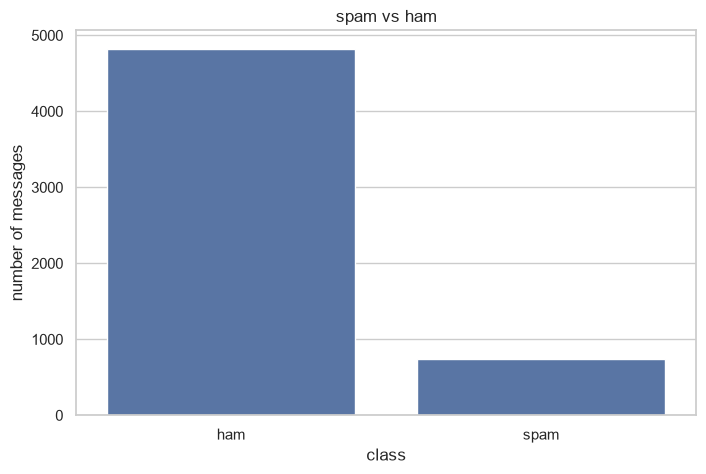

In [15]:
sns.countplot(data=data, x='label')
plt.title('spam vs ham')
plt.xlabel('class')
plt.ylabel('number of messages')
plt.show()

In [17]:
data['message_length'] = data['message'].str.len()
data[['message', 'message_length']].head()

,message,message_length
0,"Go until jurong point, crazy.. Available only ...",111
1,Ok lar... Joking wif u oni...,29
2,Free entry in 2 a wkly comp to win FA Cup fina...,155
3,U dun say so early hor... U c already then say...,49
4,"Nah I don't think he goes to usf, he lives aro...",61


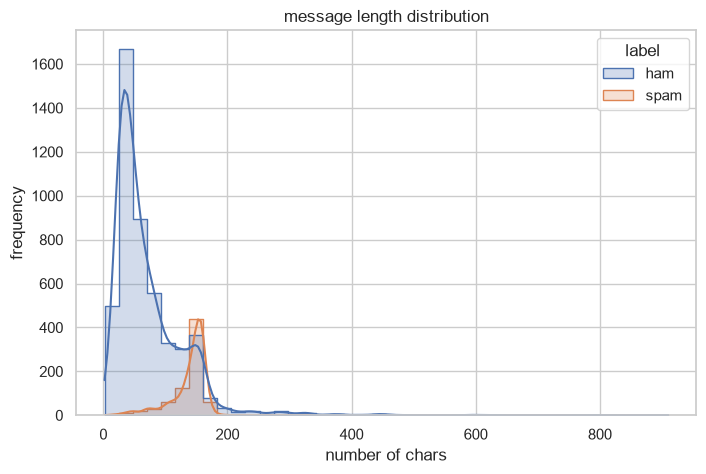

In [18]:
sns.histplot(data=data, x='message_length', hue='label', bins=40, kde=True, element='step')
plt.title('message length distribution')
plt.xlabel('number of chars')
plt.ylabel('frequency')
plt.show()

In [19]:
from collections import Counter

words = ' '.join(data['message']).lower().split()
word_counts = Counter(words)
most_common = word_counts.most_common(15)
word_data = pd.DataFrame(most_common, columns=['word', 'count'])

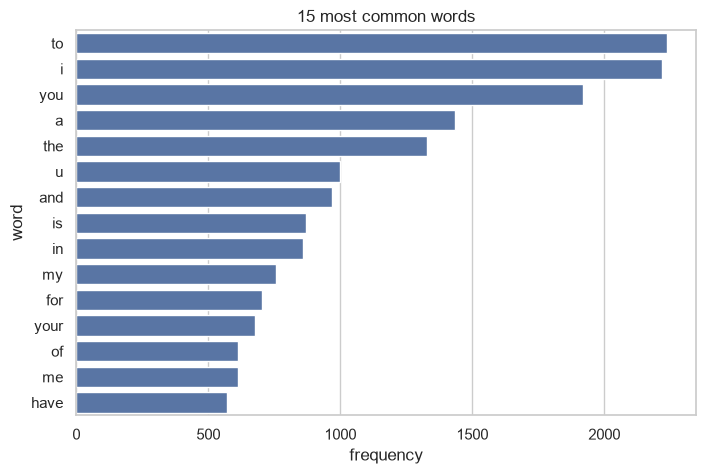

In [20]:
sns.barplot(data=word_data, x='count', y='word')
plt.title('15 most common words')
plt.xlabel('frequency')
plt.ylabel('word')
plt.show()

In [21]:
duplicates = data[data.duplicated(keep=False)].sort_values('message')
duplicates.head()

,label,message,message_length
505,spam,+123 Congratulations - in this week's competit...,169
2124,spam,+123 Congratulations - in this week's competit...,169
2344,ham,1) Go to write msg 2) Put on Dictionary mode 3...,141
1373,ham,1) Go to write msg 2) Put on Dictionary mode 3...,141
2163,ham,1) Go to write msg 2) Put on Dictionary mode 3...,141


In [22]:
label_counts = data.groupby('message')['label'].nunique()
label_counts.value_counts()

label
1    5169
Name: count, dtype: int64

In [23]:
data = data.drop_duplicates().reset_index(drop=True)
print(data.shape)
print(data['label'].shape)

(5169, 3)
(5169,)


In [24]:
from sklearn.model_selection import train_test_split

x = data['message']
y = data['label']

x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42, stratify=y)

In [25]:
from sklearn.feature_extraction.text import CountVectorizer

sample_messages = ['I like cats', 'Cats like catfood', 'Cats are cute']

vectorizer_demo = CountVectorizer()
sample_matrix = vectorizer_demo.fit_transform(sample_messages)

print(vectorizer_demo.get_feature_names_out())
print('\n', sample_matrix.toarray())

['are' 'catfood' 'cats' 'cute' 'like']

 [[0 0 1 0 1]
 [0 1 1 0 1]
 [1 0 1 1 0]]


In [26]:
vectorizer = CountVectorizer()

x_train_vec = vectorizer.fit_transform(x_train)
x_test_vec = vectorizer.transform(x_test)

print(x_train_vec.shape, x_test_vec.shape)
print(len(vectorizer.get_feature_names_out()))

(4135, 7680) (1034, 7680)
7680


In [27]:
print(x_train.iloc[:3])

331      Ta-Daaaaa! I am home babe, are you still up ?
383    Yup having my lunch buffet now.. U eat already?
573     Ok anyway no need to change with what you said
Name: message, dtype: str


In [29]:
feature_names = vectorizer.get_feature_names_out()

sample_data = pd.DataFrame(x_train_vec[:3].toarray(), columns = feature_names)
sample_data

,00,000,000pes,008704050406,0089,0121,01223585236,01223585334,0125698789,02,...,zhong,zindgi,zoe,zogtorius,zoom,zouk,zyada,èn,ú1,〨ud
0,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [30]:
from sklearn.naive_bayes import MultinomialNB

model = MultinomialNB(alpha=1.0)
model.fit(x_train_vec, y_train)

,"alpha alpha: float or array-like of shape (n_features,), default=1.0Additive (Laplace/Lidstone) smoothing parameter(set alpha=0 and force_alpha=True, for no smoothing).",1.0
,"force_alpha force_alpha: bool, default=TrueIf False and alpha is less than 1e-10, it will set alpha to1e-10. If True, alpha will remain unchanged. This may causenumerical errors if alpha is too close to 0... versionadded:: 1.2.. versionchanged:: 1.4 The default value of `force_alpha` changed to `True`.",True
,"fit_prior fit_prior: bool, default=TrueWhether to learn class prior probabilities or not.If false, a uniform prior will be used.",True
,"class_prior class_prior: array-like of shape (n_classes,), default=NonePrior probabilities of the classes. If specified, the priors are notadjusted according to the data.",None
Name,Type,Value
"class_count_ class_count_: ndarray of shape (n_classes,)Number of samples encountered for each class during fitting. Thisvalue is weighted by the sample weight when provided.","ndarray[float64](2,)","[3613., 522.]"
"class_log_prior_ class_log_prior_: ndarray of shape (n_classes,)Smoothed empirical log probability for each class.","ndarray[float64](2,)","[-0.13,-2.07]"
"classes_ classes_: ndarray of shape (n_classes,)Class labels known to the classifier","ndarray[<U4](2,)","['ham','spam']"
"feature_count_ feature_count_: ndarray of shape (n_classes, n_features)Number of samples encountered for each (class, feature)during fitting. This value is weighted by the sample weight whenprovided.","ndarray[float64](2, 7680)","[[ 0., 0., 1.,..., 1., 0., 1.], [ 7.,23., 0.,..., 0., 1., 0.]]"
"feature_log_prob_ feature_log_prob_: ndarray of shape (n_classes, n_features)Empirical log probability of featuresgiven a class, ``P(x_i|y)``.","ndarray[float64](2, 7680)","[[-10.91,-10.91,-10.22,...,-10.22,-10.91,-10.22], [ -7.82, -6.72, -9.9 ,..., -9.9 , -9.2 , -9.9 ]]"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,7680


In [31]:
y_pred = model.predict(x_test_vec)
print(y_pred[:10])
print(y_test.iloc[:10].to_numpy())

['ham' 'ham' 'ham' 'ham' 'ham' 'ham' 'ham' 'ham' 'ham' 'ham']
['ham' 'ham' 'ham' 'ham' 'ham' 'ham' 'ham' 'ham' 'ham' 'ham']


In [35]:
from sklearn.metrics import (accuracy_score, confusion_matrix, classification_report)

print('accuracy:', accuracy_score(y_pred, y_test))
print('\nconfusion matrix:\n', confusion_matrix(y_test, y_pred))
print('\nclassification report:\n', classification_report(y_test, y_pred))

accuracy: 0.9816247582205029

confusion matrix:
 [[898   5]
 [ 14 117]]

classification report:
               precision    recall  f1-score   support

         ham       0.98      0.99      0.99       903
        spam       0.96      0.89      0.92       131

    accuracy                           0.98      1034
   macro avg       0.97      0.94      0.96      1034
weighted avg       0.98      0.98      0.98      1034



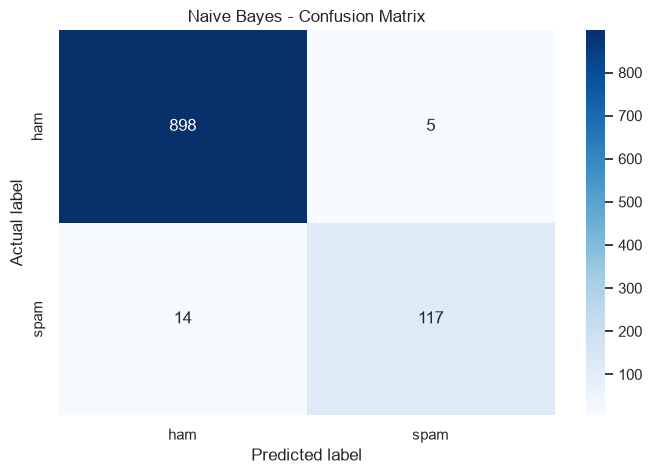

In [37]:
cm = confusion_matrix(y_test, y_pred)

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=model.classes_,
    yticklabels=model.classes_
)

plt.xlabel("Predicted label")
plt.ylabel("Actual label")
plt.title("Naive Bayes - Confusion Matrix")
plt.show()

In [38]:
probabilities = model.predict_proba(x_test_vec)
print(probabilities[:10])
print(model.classes_)

[[1.00000000e+00 1.09839292e-18]
 [9.99998442e-01 1.55762006e-06]
 [9.99986163e-01 1.38374695e-05]
 [9.99856578e-01 1.43421796e-04]
 [9.99999972e-01 2.84454504e-08]
 [9.99999438e-01 5.61637915e-07]
 [9.99999976e-01 2.40115769e-08]
 [1.00000000e+00 4.54857650e-15]
 [9.99973247e-01 2.67528812e-05]
 [9.99993022e-01 6.97764227e-06]]
['ham' 'spam']


ROC-AUC:
 0.9803538670927274


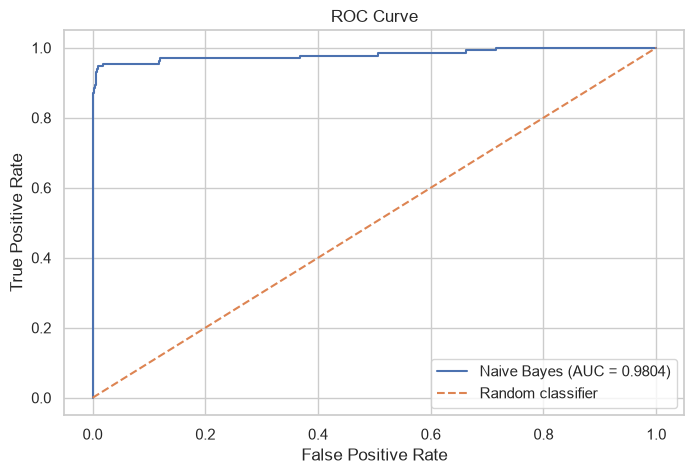

In [39]:
from sklearn.metrics import roc_curve, roc_auc_score

y_proba = model.predict_proba(x_test_vec)[:, 1]
fpr, tpr, thresholds = roc_curve(y_test, y_proba, pos_label='spam')
auc = roc_auc_score(y_test, y_proba)
print('ROC-AUC:\n', auc)

plt.plot(fpr, tpr, label=f"Naive Bayes (AUC = {auc:.4f})")
plt.plot([0, 1], [0, 1], linestyle="--", label="Random classifier")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")
plt.legend()
plt.show()